# How does an airports location to the equator affect its traffic?
## Connor Kowalski
## 11/14/26

### Dataset: World airports JSON. Top 30 busiest airports from the jsonlint source provided in the assignment details.

### Link: https://jsonlint.com/datasets/airports

### Why I chose it: Airports have coordinates for their locations which make them easy to graph and locate their distance from the equator. Each row will be its own international airport.

### Vairables to investigate: latitude, longitude, absLatitude, region 

### Research question: Do the busiest airports in the US sit farther from the equator than the busiest airports in the rest of the world?

### Hypothesis: The average latitude of American airports is higher than the average latitude of internationa; airports. Most American airports are further from the equator while others are closer to middle latitudes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

#read and normalize the json file

df = pd.read_json("airports.json")
df = pd.json_normalize(df["airports"])

df.head()

,code,name,city,country,lat,lon
0,ATL,Hartsfield-Jackson Atlanta International,Atlanta,US,33.6407,-84.4277
1,PEK,Beijing Capital International,Beijing,CN,40.0801,116.5846
2,DXB,Dubai International,Dubai,AE,25.2528,55.3644
3,LAX,Los Angeles International,Los Angeles,US,33.9425,-118.4081
4,HND,Tokyo Haneda,Tokyo,JP,35.5494,139.7798


In [2]:
df.shape

(30, 6)

In [3]:
df.info()
# structure of the cells and data types

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   code     30 non-null     str    
 1   name     30 non-null     str    
 2   city     30 non-null     str    
 3   country  30 non-null     str    
 4   lat      30 non-null     float64
 5   lon      30 non-null     float64
dtypes: float64(2), str(4)
memory usage: 1.5 KB


In [4]:
df.describe()
# coordinates of each rows location

,lat,lon
count,30.000000,30.000000
mean,31.951923,16.402787
std,17.946009,93.216910
min,-33.939900,-122.379000
25%,25.388575,-80.121450
50%,36.616100,6.665250
75%,41.291875,110.971975
max,52.310500,151.175300


In [5]:
df["country"].value_counts()

usAirports = df[df["country"] == "US"]
otherAirports = df[df["country"] != "US"]

usLat = usAirports["lat"]
otherLat = otherAirports["lat"]

print(usLat.agg(["count", "mean", "median", "std"]))
print(otherLat.agg(["count", "mean", "median", "std"]))

# claude said it was better to use .agg instead of groupby because it kept causing problems.

count      8.000000
mean      35.796475
median    35.781900
std        5.317545
Name: lat, dtype: float64
count     22.000000
mean      30.553905
median    36.616100
std       20.679575
Name: lat, dtype: float64


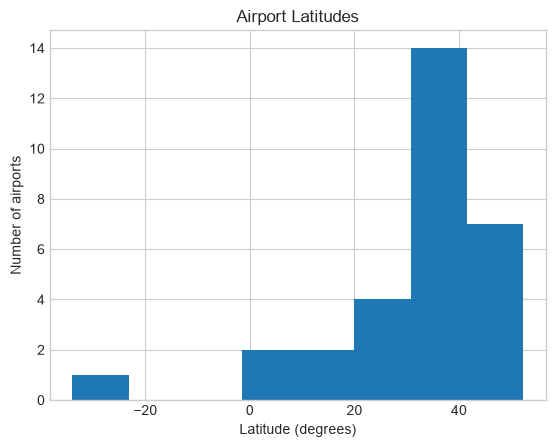

In [21]:
plt.hist(df["lat"], bins=8)
plt.xlabel("Latitude (degrees)")
plt.ylabel("Number of airports")
plt.title("Airport Latitudes")
plt.show()
#histogram

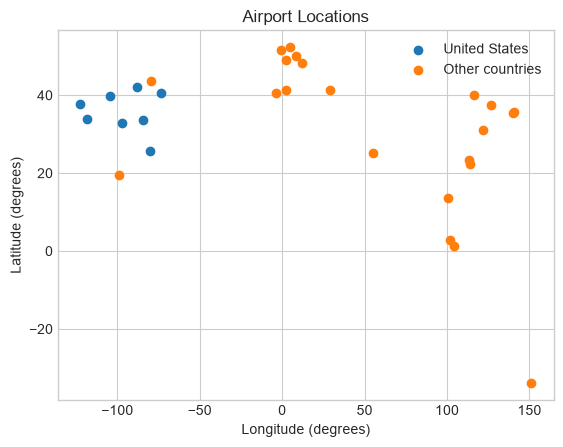

In [30]:
plt.scatter(usAirports["lon"], usAirports["lat"], label="United States")
plt.scatter(otherAirports["lon"], otherAirports["lat"], label="Other countries")

plt.xlabel("Longitude (degrees)")
plt.ylabel("Latitude (degrees)")
plt.title("Airport Locations")
plt.legend()
plt.show()
#scatterplot comparison

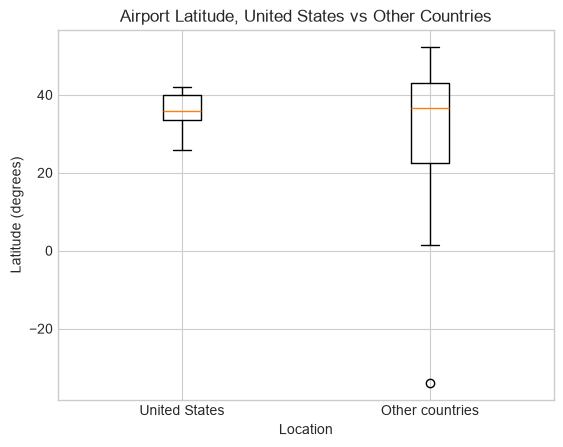

In [19]:
plt.boxplot(
    [usLat, otherLat],
    tick_labels=["United States", "Other countries"]
)

plt.xlabel("Location")
plt.ylabel("Latitude (degrees)")
plt.title("Airport Latitude, United States vs Other Countries")
plt.show()
#boxplot data

In [20]:
plt.style.use("seaborn-v0_8-whitegrid") #wow new style that we learned in class

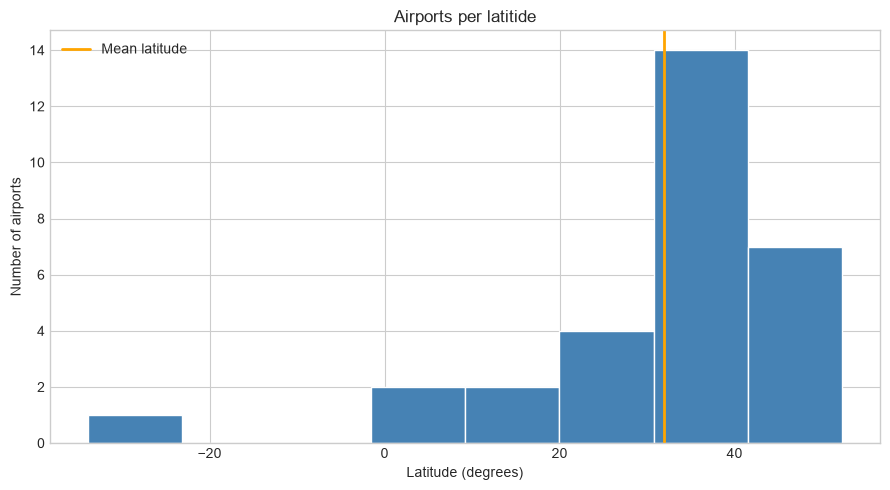

In [29]:
plt.figure(figsize=(9, 5))
plt.hist(df["lat"], bins=8, color="steelblue", edgecolor="white")

plt.axvline(df["lat"].mean(), color="orange", linewidth=2, label="Mean latitude")

plt.xlabel("Latitude (degrees)")
plt.ylabel("Number of airports")
plt.title("Airports per latitide")
plt.legend()
plt.tight_layout()
plt.show()
#much better styled and readable graph. Styling curdious of in class november 8th

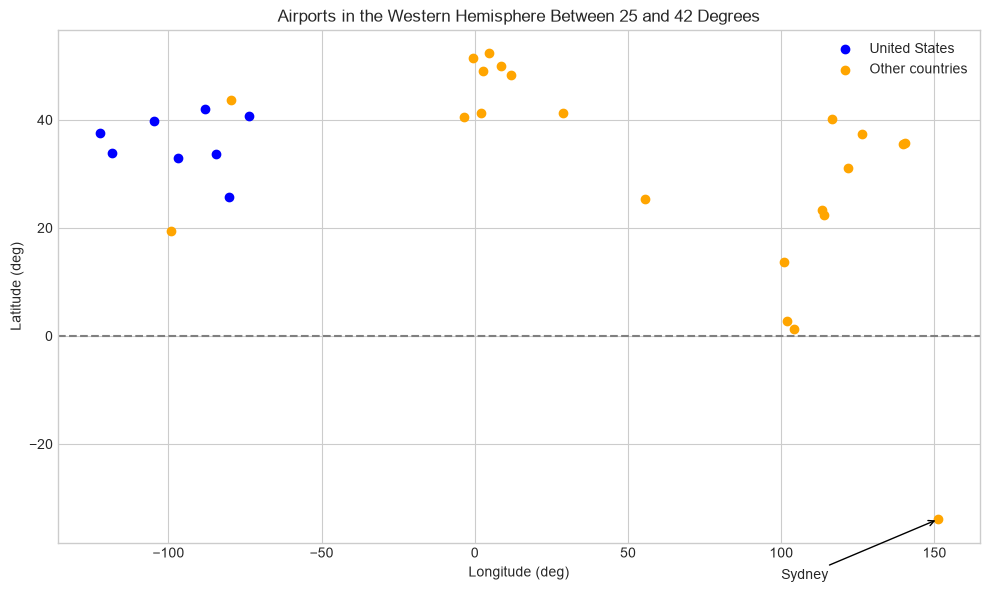

In [22]:
plt.figure(figsize=(10, 6))

plt.scatter(usAirports["lon"], usAirports["lat"], color="blue", label="United States")
plt.scatter(otherAirports["lon"], otherAirports["lat"], color="orange", label="Other countries")

plt.axhline(0, color="gray", linestyle="--")   # equator
plt.annotate("Sydney", xy=(151.18, -33.94), xytext=(100, -45),
             arrowprops=dict(arrowstyle="->"))
#it was hard doing the label for this so claude was a big help

plt.xlabel("Longitude (deg)")
plt.ylabel("Latitude (deg)")
plt.title("Airports in the Western Hemisphere Between 25 and 42 Degrees")
plt.legend()
plt.tight_layout()
plt.show()

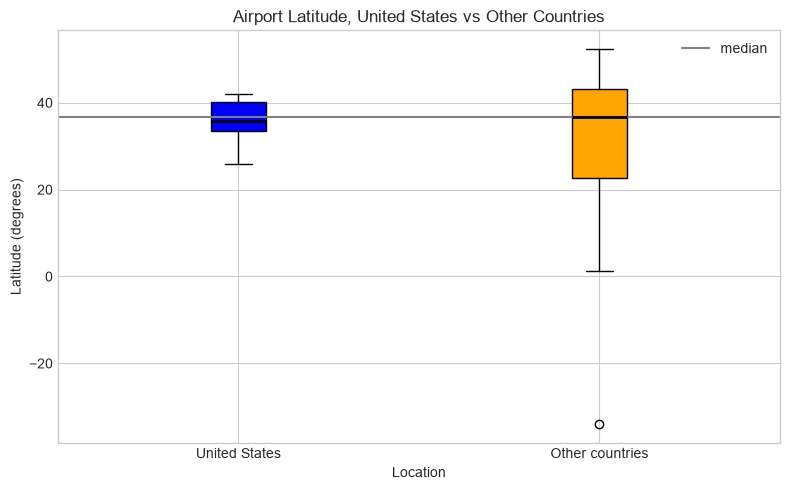

In [28]:
plt.figure(figsize=(8, 5))

boxes = plt.boxplot(
    [usLat, otherLat],
    tick_labels=["United States", "Other countries"],
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2)
)

boxes["boxes"][0].set_facecolor("blue")
boxes["boxes"][1].set_facecolor("orange")

plt.axhline(df["lat"].median(), color="gray", label="median")

plt.xlabel("Location")
plt.ylabel("Latitude (degrees)")
plt.title("Airport Latitude, United States vs Other Countries")
plt.legend()
plt.tight_layout()
plt.show()

In [31]:
modelA = ols(
    "lat ~ C(country == 'US')",
    data=df
).fit()

print(modelA.summary())

                            OLS Regression Results                            
Dep. Variable:                    lat   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                 -0.018
Method:                 Least Squares   F-statistic:                    0.4919
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.489
Time:                        16:23:38   Log-Likelihood:                -128.42
No. Observations:                  30   AIC:                             260.8
Df Residuals:                      28   BIC:                             263.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

## Analysis:
Option A, compare two groups.
Vairables: Y vairable is lat and X is if the airport is located in the US or not.
The y-intercept is 30.55 which is the average latitude of the international airports. The coefficent for US airports is 5.24 meaning the average US airport is 5.24 degrees further north than other airports.
The p-value is 0.489 so this is much larger than the 5% confidence level so this data isn't very trusted or significant.
The results do not spport the hypothesis because the hypothesis stated that US airports are further north but the difference is so small that it doesn't really answer the question too well. 
Limits and assumptions:
The sample is pretty small, especially only having 8 airports in the US. The international group also includes airports that may be further away from the equator, lowering the average for all other airports closer.

## Conclusion:
From analyzing this dataset I learned that most of the busiest airports are in the northern hemisphere and that US airports are not higher in latitude than foreign airports. My findings did not support my hypothesis because I thought American airports would have a higher latitude but the data showed otherwise. The scatterplot helped visualize the airports and they even form a bit of a world map if you use the dots as a general location. The analysis showed the raw values and how they play in with eachother and I was surprised to see how close it was in latitude. Maybe some o